# TD6 — Exercice 2 : Variogramme 2D sur la grille image (Voxet)

Cet exercice étudie la variable **Values** sur une **grille image 2D (Voxet 100×100)**,
à partir du fichier `image_2D_grille.csv` (10 000 cellules). **Nature de la donnée** : `Values` est une **variable régionalisée standardisée** (moyenne ≈ 0, variance ≈ 1), fournie sur une **grille 2D complète** (10 000 cellules). Donnée pédagogique servant à étudier la structure spatiale lorsque la variable est connue partout.

## Aperçu des fonctions utilisées

Petit récapitulatif de ce que fait chaque fonction clé de ce notebook :

| Fonction | Rôle |
|---|---|
| `pd.read_csv(...)` | Charge la grille image 2D (variable `Values`) |
| `reshape(...)` + `plt.imshow(...)` | Reconstruit et affiche l'**image** 100×100 |
| `gl.defineDefaultSpace(RN, 2)` | Définit l'espace de travail en **2D** |
| `gl.DbGrid.create(...)` + `addColumns(...)` | Crée la base **grille** gstlearn et y ajoute la variable |
| `gl.VarioParam.createOmniDirection(...)` | Définit les paramètres du variogramme omnidirectionnel |
| `gl.Vario.compute(...)` | Calcule le variogramme **expérimental** |
| `gl.Model().fit(...)` | Ajuste un **modèle théorique** (sphérique) |
| `gl.DirParam.create(...)` | Calcule le variogramme **directionnel** (étude de l'anisotropie) |


## 1. Chargement des données

Lecture du fichier `image_2D_grille.csv` (grille 2D, 10 000 cellules).

In [1]:
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import gstlearn as gl
import gstlearn.plot as gp
import ipywidgets as widgets
from ipywidgets import interactive_output

sys.path.append(os.path.abspath(os.path.join("..", "..")))
import geostat_utils as gutils

# ---- Chargement des données (Exercice 2 : grille image 2D) ----
voxet_2D = pd.read_csv('../../../data/image_2D_grille.csv')
valeurs_grille = voxet_2D['Values'].to_numpy()
display(voxet_2D.head(3))

# ---- Dossier de sauvegarde des figures ----
DOSSIER_SORTIE = "../../../outputs/gold"
os.makedirs(DOSSIER_SORTIE, exist_ok=True)

,Values
0,1.859476
1,2.726281
2,2.155685


## 2. Visualisation de la grille image 2D

### Contexte

Les données proviennent du **Voxet 2DMap** exporté depuis SKUA-Gocad. La grille contient **10 000 cellules ** avec une propriété **Values**.

### 2.1 Visualisation de la grille image 2D (Voxet 100×100)

Chaque cellule correspond à une valeur de la propriété **Values**.La colormap **PRGn** (Purple-Green) est utilisée — même palette que SKUA.

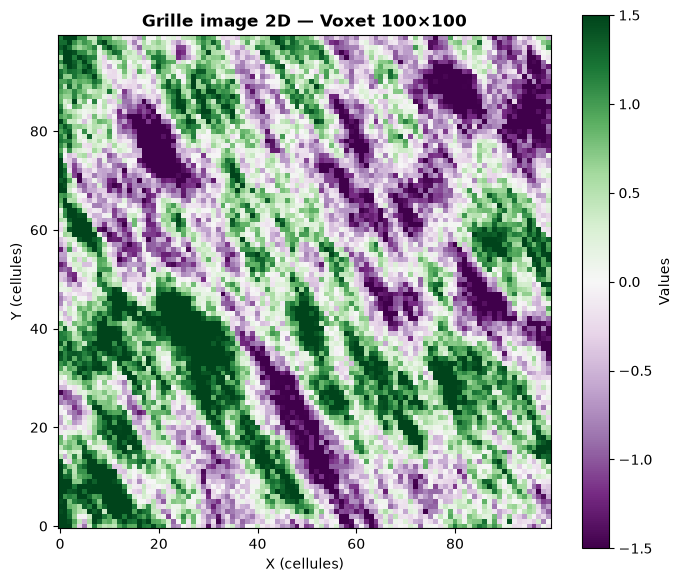

In [2]:
# ---- Reconstruction de la grille 100×100 ----
nx_map, ny_map = 100, 100
grid_image = valeurs_grille.reshape(ny_map, nx_map)
# ---- Affichage de l'image 2D ------
plt.figure(figsize=(7, 6))
plt.imshow(grid_image, cmap='PRGn', origin='lower',
           vmin=-1.5, vmax=1.5)
plt.colorbar(label='Values')
plt.title('Grille image 2D — Voxet 100×100', fontweight='bold')
plt.xlabel('X (cellules)')
plt.ylabel('Y (cellules)')
plt.tight_layout()
plt.savefig(f"{DOSSIER_SORTIE}/ex2_grille_image.png", dpi=150, bbox_inches="tight")
plt.show()

## 3. Création de la base gstlearn (grille 2DMap)

In [3]:
# ---- Création de la base gstlearn depuis la grille 2DMap ----
# ---- Paramètres du variogramme 2D ----
gl.defineDefaultSpace(gl.ESpaceType.RN, 2)
nombre_lags_2d = 15
taille_lag_2d  = 0.165 
grid_2dmap = gl.DbGrid.create(
    [nx_map, ny_map],    
    [taille_lag_2d, taille_lag_2d],          
    [0.0, 0.0]           
)
err = grid_2dmap.addColumns(valeurs_grille, 'Values', gl.ELoc.Z)
print(grid_2dmap)


Data Base Grid Characteristics

Data Base Summary
-----------------
File is organized as a regular grid
Space dimension              = 2
Number of Columns            = 4
Total number of samples      = 10000

Grid characteristics:
---------------------
Origin :       0.000      0.000
Mesh   :       0.165      0.165
Number :         100        100

Variables
---------
Column = 0 - Name = rank - Locator = NA
Column = 1 - Name = x1 - Locator = x1
Column = 2 - Name = x2 - Locator = x2
Column = 3 - Name = Values - Locator = z1



## 4. Variogramme expérimental en 2D

### 4.1 Calcul et affichage du variogramme

In [4]:
# ---- Calcul variogramme omnidirectionnel en 2d----
params_vario_2dmap = gl.VarioParam.createOmniDirection(
    nlag=nombre_lags_2d,
    dlag=taille_lag_2d
)
vario_2dmap = gl.Vario(params_vario_2dmap)
err = vario_2dmap.compute(grid_2dmap)
print(f"Erreur calcul : {err}")
print(vario_2dmap)

Erreur calcul : 0

Variogram characteristics
Number of variable(s)       = 1
Number of direction(s)      = 1
Space dimension             = 2
Variable(s)                 = [Values]

Variance-Covariance Matrix      0.937

Direction #1
------------
Number of lags              = 15
Direction coefficients      =       1.000      0.000
Direction angles (degrees)  =       0.000
Tolerance on direction      =      90.000 (degrees)
Calculation lag             =       0.165
Tolerance on distance       =      50.000 (Percent of the lag value)

For variable 1
       Rank     Npairs   Distance      Value
          1  39402.000      0.199      0.151
          2  58408.000      0.356      0.254
          3  77020.000      0.501      0.340
          4 151690.000      0.673      0.426
          5 131108.000      0.848      0.510
          6 184644.000      1.005      0.571
          7 182502.000      1.165      0.631
          8 216084.000      1.321      0.680
          9 301508.000      1.495      0.7

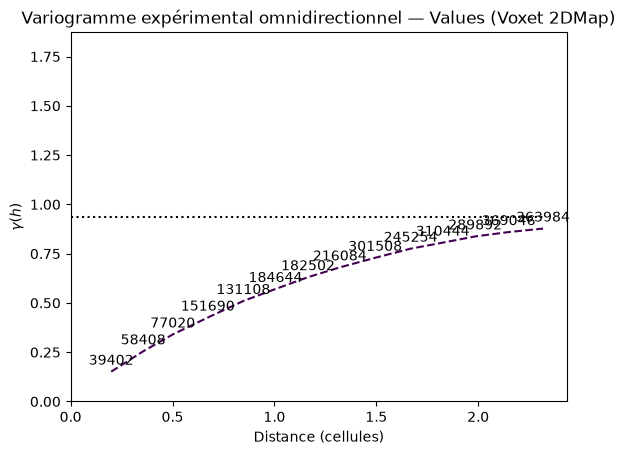

In [5]:
#---- Affichage du variogramme expérimental 2D ----
variance_2dmap = float(np.var(valeurs_grille, ddof=1))
ax = gp.varmod(vario_2dmap, showPairs=True)
ax.set_ylim(0, variance_2dmap * 2)
plt.xlabel("Distance (cellules)")
plt.ylabel(r"$\gamma(h)$")
plt.title("Variogramme expérimental omnidirectionnel — Values (Voxet 2DMap)")
plt.show()

## 5. Ajustement automatique du modèle

### 5.1 Modèle Sphérique sans nugget

Le modèle **Sphérique sans nugget** est ajusté automatiquement :

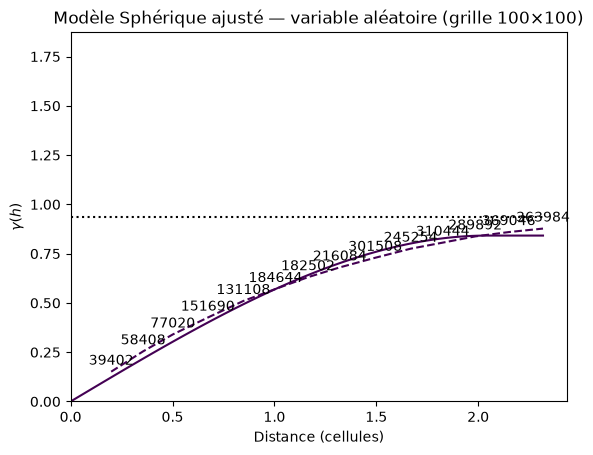


Model characteristics
Space dimension              = 2
Number of variable(s)        = 1
Number of basic structure(s) = 1
Number of drift function(s)  = 0
Number of drift equation(s)  = 0

Covariance Part
---------------
Spherical
- Sill         =       0.842
- Range        =       2.046
Total Sill     =       0.842
Known Mean(s)      0.000



In [7]:
# ---- Ajustement modèle Sphérique ----
model_sph_2dmap = gl.Model()
err = model_sph_2dmap.fit(vario_2dmap, types=[gl.ECov.SPHERICAL])
gutils.afficher_variogramme(
    vario_2dmap, model_sph_2dmap,
    "Modèle Sphérique ajusté — variable aléatoire (grille 100×100)",
    variance_2dmap,
    unite="cellules"
)

## 6. Carte variographique (Variogram Map)

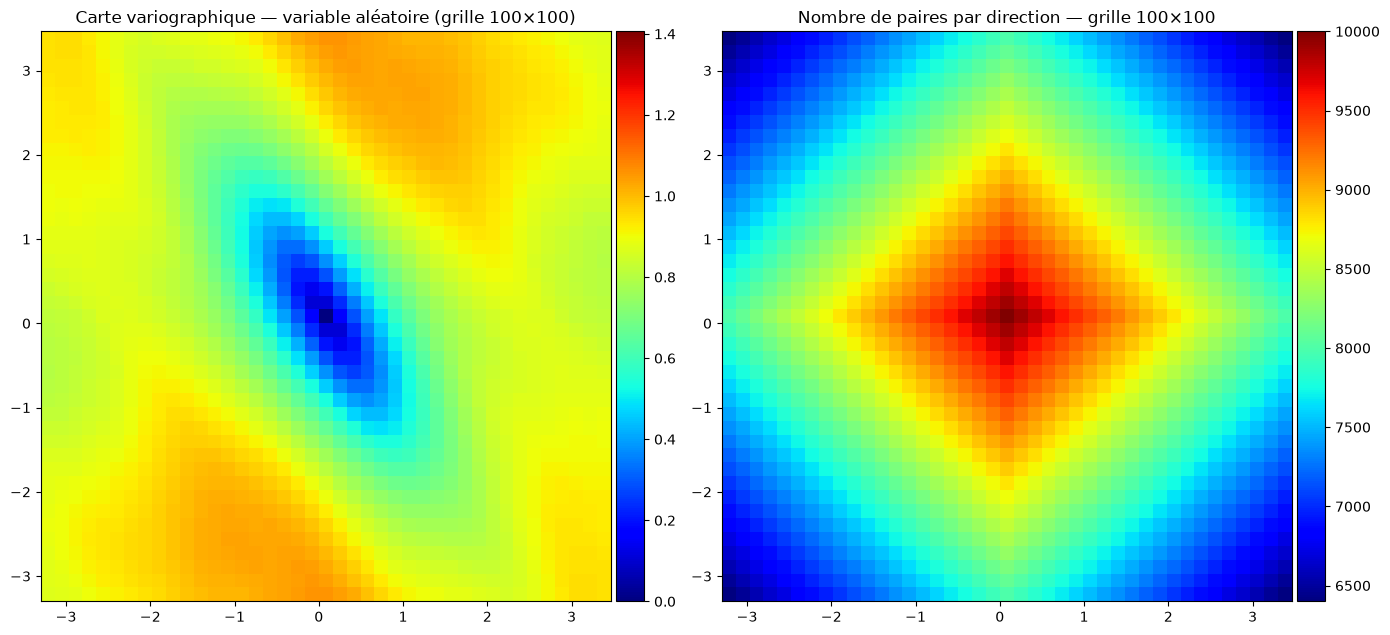

In [8]:
#----Affichage de la Carte variographique (Variogram Map) — grille 100×100----
# simultanément pour identifier les directions d'anisotropie

grid_map_2dmap = gl.db_vmap(grid_2dmap)
fig, ax = gp.init(1, 2, figsize=(14, 7), flagEqual=True)
ax[0].raster(grid_map_2dmap, flagLegend=True, cmap="jet", vmin=0, vmax=variance_2dmap * 1.5)
ax[0].decoration(title="Carte variographique — variable aléatoire (grille 100×100)")

#-----carte du nombre de paires -----
ax[1].raster(grid_map_2dmap, name="VMAP.Values.Nb", flagLegend=True, cmap="jet")
ax[1].decoration(title="Nombre de paires par direction — grille 100×100")
plt.tight_layout()
plt.show()

## 7. Variogramme directionnel (anisotropie)

La carte variographique montre une anisotropie dans la direction diagonale.On calcule le variogramme dans **2 directions** :

- **Direction 135°** — direction principale (grande portée)

- **Direction 45°** — direction perpendiculaire (petite portée)

Erreur calcul : 0


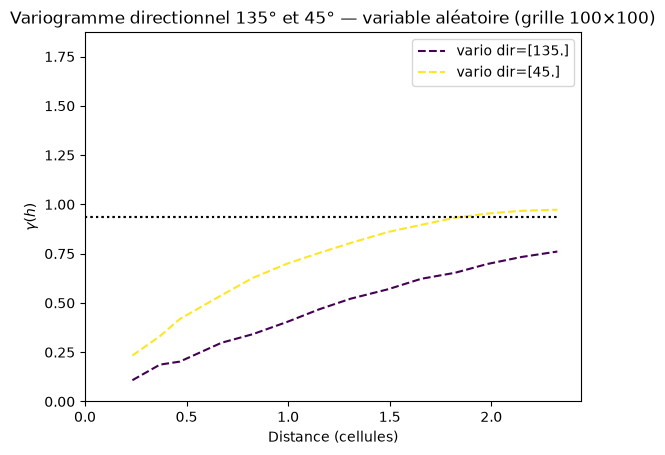

In [9]:
#---- Variogramme directionnel en deux directions ----
params_vario_dir = gl.VarioParam()
# Direction 135° — direction principale
dir_135 = gl.DirParam.create(
    nlag=nombre_lags_2d,
    dlag=taille_lag_2d,
    tolang=22.5,
    codir=[-1, 1]    
)
# Direction 45° — direction perpendiculaire
dir_45 = gl.DirParam.create(
    nlag=nombre_lags_2d,
    dlag=taille_lag_2d,
    tolang=22.5,
    codir=[1, 1]     
)
params_vario_dir.addDir(dir_135)
params_vario_dir.addDir(dir_45)

vario_dir = gl.Vario(params_vario_dir)
err = vario_dir.compute(grid_2dmap)
print(f"Erreur calcul : {err}")

ax = gp.varmod(vario_dir, flagLegend=True)
ax.set_ylim(0, variance_2dmap * 2)
plt.xlabel("Distance (cellules)")
plt.ylabel(r"$\gamma(h)$")
plt.title("Variogramme directionnel 135° et 45° — variable aléatoire (grille 100×100)")
plt.show()